# Notebook 1 · Données (J1) · Étapes 1 et 2 : collecte et préparation

**Sujet 18 · Intentions d'achat sur un site marchand.** Repérer, pendant la visite, les sessions qui vont se terminer par un achat.

| Étape du cycle | Partie du notebook |
| --- | --- |
| 1 · Collecte | Partie 1 : charger les données officielles, contrôler leur qualité, explorer |
| 2 · Préparation | Partie 2 : nettoyer, séparer train / test **avant** de préparer, encoder et normaliser |

Exécutez les cellules dans l'ordre, de haut en bas.

In [1]:
# Imports (toutes ces bibliothèques sont déjà installées dans Colab)
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.4.6


## 0. Mise en place (identique dans les trois notebooks)

In [2]:
# ===================== CONFIG : identique dans les 3 notebooks =====================
# Si vous modifiez une valeur ici, modifiez-la aussi dans les deux autres notebooks.
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv"
LOCAL_PATH = "online_shoppers_intention.csv"   # utilisé si le fichier a été téléversé dans Colab

TARGET = "Revenue"
NUM_COLS = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "SpecialDay",
]
LEAKY_COL = "PageValues"   # calculée à partir des transactions : testée avec et sans
CAT_COLS = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
BOOL_COLS = ["Weekend"]

FEATURE_SETS = {
    "sans_PageValues": NUM_COLS + CAT_COLS + BOOL_COLS,
    "avec_PageValues": NUM_COLS + [LEAKY_COL] + CAT_COLS + BOOL_COLS,
}

# Garde-fou : les 3 notebooks doivent obtenir exactement le même découpage.
EXPECTED_SPLIT = (9764, 2441)   # (lignes d'entraînement, lignes de test)

In [3]:
# ===================== FONCTIONS COMMUNES : identiques dans les 3 notebooks =====================
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def load_raw():
    """Étape 1 : charge le CSV officiel (fichier local, sinon page UCI, sinon téléversement)."""
    if Path(LOCAL_PATH).exists():
        return pd.read_csv(LOCAL_PATH)
    try:
        return pd.read_csv(DATA_URL)
    except Exception as err:
        print("Téléchargement impossible :", err, "-> téléversez online_shoppers_intention.csv")
        from google.colab import files
        files.upload()
        return pd.read_csv(LOCAL_PATH)


def clean(df):
    """Nettoyage sans apprentissage (aucune statistique calculée) : sûr avant le découpage."""
    df = df.copy()
    df["Month"] = df["Month"].replace({"June": "Jun"})   # seul mois écrit en entier
    df["Weekend"] = df["Weekend"].astype(int)
    df[TARGET] = df[TARGET].astype(int)
    for col in CAT_COLS:                                 # les codes sont des catégories
        df[col] = df[col].astype(str)
    return df.drop_duplicates().reset_index(drop=True)   # avant le découpage, sinon fuite


def split(df):
    """Découpage stratifié, toujours avec la même graine."""
    X = df.drop(columns=TARGET)
    y = df[TARGET]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
    assert (len(X_train), len(X_test)) == EXPECTED_SPLIT, "Découpage différent des autres notebooks !"
    return X_train, X_test, y_train, y_test


def make_preprocessor(feature_set):
    """Étape 2 : à n'ajuster que sur l'entraînement (ou dans un Pipeline)."""
    num = [c for c in FEATURE_SETS[feature_set] if c in NUM_COLS + [LEAKY_COL]]
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ("bool", "passthrough", BOOL_COLS),
    ], remainder="drop")   # remainder="drop" retire PageValues dans la variante « sans »


def build_estimator(name, params=None):
    """Étape 3 : les modèles candidats."""
    estimator = {
        "Reference_naive": DummyClassifier(strategy="most_frequent"),
        "Regression_logistique": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "Foret_aleatoire": RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient_boosting": HistGradientBoostingClassifier(
            class_weight="balanced", random_state=RANDOM_STATE),
    }[name]
    if params:
        estimator.set_params(**params)
    return estimator


def make_pipeline(name, feature_set, params=None):
    return Pipeline([("prep", make_preprocessor(feature_set)),
                     ("model", build_estimator(name, params))])


CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Partie 1 · Collecte

### 1.1 Premier contact

In [4]:
raw = load_raw()
print(raw.shape)
raw.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### 1.2 Qualité : types, valeurs manquantes, doublons

In [5]:
raw.info()
print("\nValeurs manquantes :", int(raw.isna().sum().sum()))
print("Lignes en double   :", int(raw.duplicated().sum()))
raw.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


#### 1.2 bis Les doublons : erreurs ou vraies visites ?

Avant de retirer les 125 doublons, regardons à quoi ils ressemblent.

In [6]:
dups = raw[raw.duplicated(keep=False)]
print("Lignes concernées par un doublon :", len(dups))
print("Dont achats :", int(dups[TARGET].sum()))
print("Pages produits (médiane) :", dups["ProductRelated"].median(),
      "| durée produits (médiane) :", dups["ProductRelated_Duration"].median(), "s")
print("Taux de rebond = 0,2 (rebond maximal) :", int((dups["BounceRates"] == 0.2).sum()), "sur", len(dups))

# Mêmes variables mais étiquette différente ? (ce serait un vrai problème de qualité)
features = [c for c in raw.columns if c != TARGET]
conflits = (raw.groupby(features)[TARGET].nunique() > 1).sum()
print("Groupes identiques avec des étiquettes contradictoires :", int(conflits))

Lignes concernées par un doublon : 201
Dont achats : 0
Pages produits (médiane) : 1.0 | durée produits (médiane) : 0.0 s
Taux de rebond = 0,2 (rebond maximal) : 201 sur 201
Groupes identiques avec des étiquettes contradictoires : 0


#### 1.2 ter Valeurs aberrantes et durées nulles

Les durées sont très étirées vers la droite : une échelle logarithmique (`log1p`) permet de voir toute la distribution.

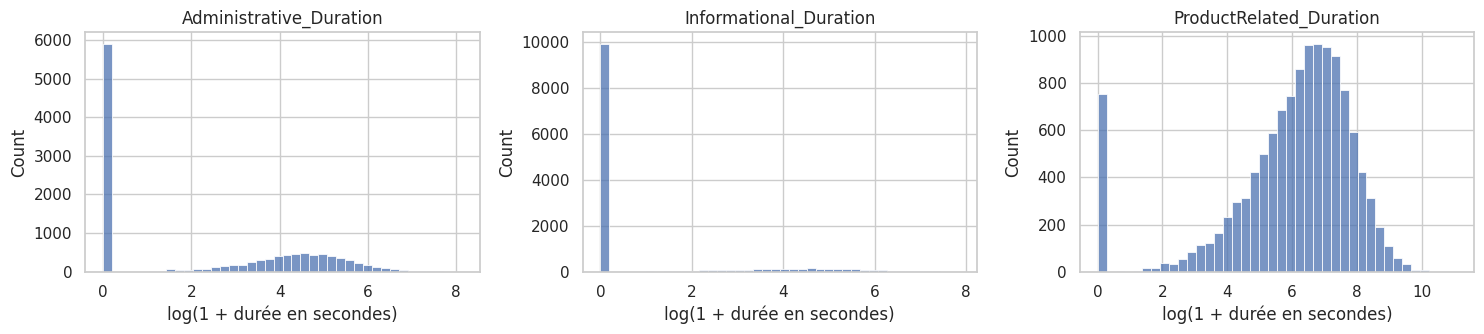

Asymétrie (skew) : {'Administrative_Duration': 5.6, 'Informational_Duration': 7.6, 'ProductRelated_Duration': 7.3}
Pages produits : médiane 10 min | 99e centile 2.4 h | max 17.8 h
Sessions de plus d'1 h sur les pages produits : 867
Sessions sans aucune page vue : 6
Administrative  pages > 0 mais durée = 0 :  135 | pages = 0 mais durée > 0 : 0
Informational   pages > 0 mais durée = 0 :  226 | pages = 0 mais durée > 0 : 0
ProductRelated  pages > 0 mais durée = 0 :  717 | pages = 0 mais durée > 0 : 0


In [7]:
DUR_COLS = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, DUR_COLS):
    sns.histplot(np.log1p(raw[col]), bins=40, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("log(1 + durée en secondes)")
plt.tight_layout()
plt.show()

print("Asymétrie (skew) :", raw[DUR_COLS].skew().round(1).to_dict())
pr = raw["ProductRelated_Duration"]
print(f"Pages produits : médiane {pr.median() / 60:.0f} min | 99e centile {pr.quantile(0.99) / 3600:.1f} h | max {pr.max() / 3600:.1f} h")
print("Sessions de plus d'1 h sur les pages produits :", int((pr > 3600).sum()))
print("Sessions sans aucune page vue :", int((raw[["Administrative", "Informational", "ProductRelated"]].sum(axis=1) == 0).sum()))

# Google Analytics ne mesure pas la durée de la dernière page vue : des pages > 0 avec une durée = 0 sont normales
for pages, duree in [("Administrative", "Administrative_Duration"), ("Informational", "Informational_Duration"),
                     ("ProductRelated", "ProductRelated_Duration")]:
    print(f"{pages:15s} pages > 0 mais durée = 0 : {int(((raw[pages] > 0) & (raw[duree] == 0)).sum()):4d}"
          f" | pages = 0 mais durée > 0 : {int(((raw[pages] == 0) & (raw[duree] > 0)).sum())}")

### 1.3 La cible : classes déséquilibrées

Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64


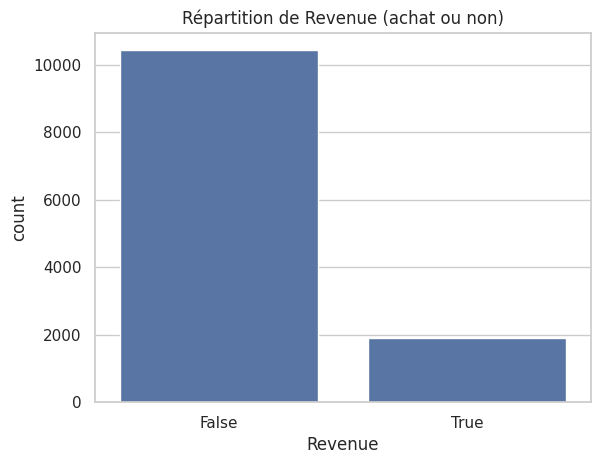

In [8]:
print(raw[TARGET].value_counts())
print(raw[TARGET].value_counts(normalize=True).round(3))
sns.countplot(x=TARGET, data=raw)
plt.title("Répartition de Revenue (achat ou non)")
plt.show()

### 1.4 Les catégories : mois et type de visiteur

In [9]:
print(raw["Month"].value_counts())       # remarque : 'June' en entier, pas de janvier ni d'avril
print(raw["VisitorType"].value_counts())

Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64


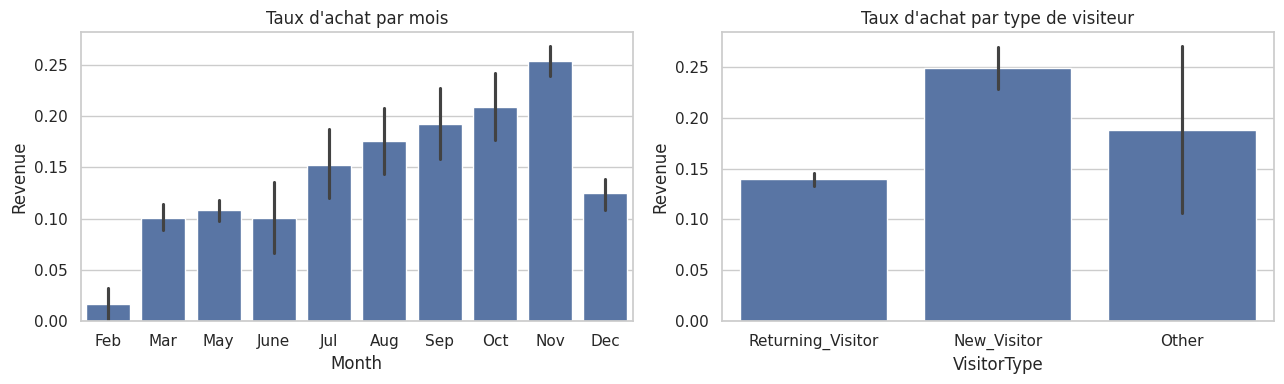

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
sns.barplot(x="Month", y=TARGET, data=raw, order=order, ax=axes[0])
axes[0].set_title("Taux d'achat par mois")
sns.barplot(x="VisitorType", y=TARGET, data=raw, ax=axes[1])
axes[1].set_title("Taux d'achat par type de visiteur")
plt.tight_layout()
plt.show()

### 1.5 Le piège `PageValues`

In [11]:
has_value = raw[LEAKY_COL] > 0
print("Taux d'achat quand PageValues > 0 :", round(raw.loc[has_value, TARGET].mean(), 3),
      "(", int(has_value.sum()), "sessions )")
print("Taux d'achat quand PageValues = 0 :", round(raw.loc[~has_value, TARGET].mean(), 3),
      "(", int((~has_value).sum()), "sessions )")

Taux d'achat quand PageValues > 0 : 0.563 ( 2730 sessions )
Taux d'achat quand PageValues = 0 : 0.039 ( 9600 sessions )


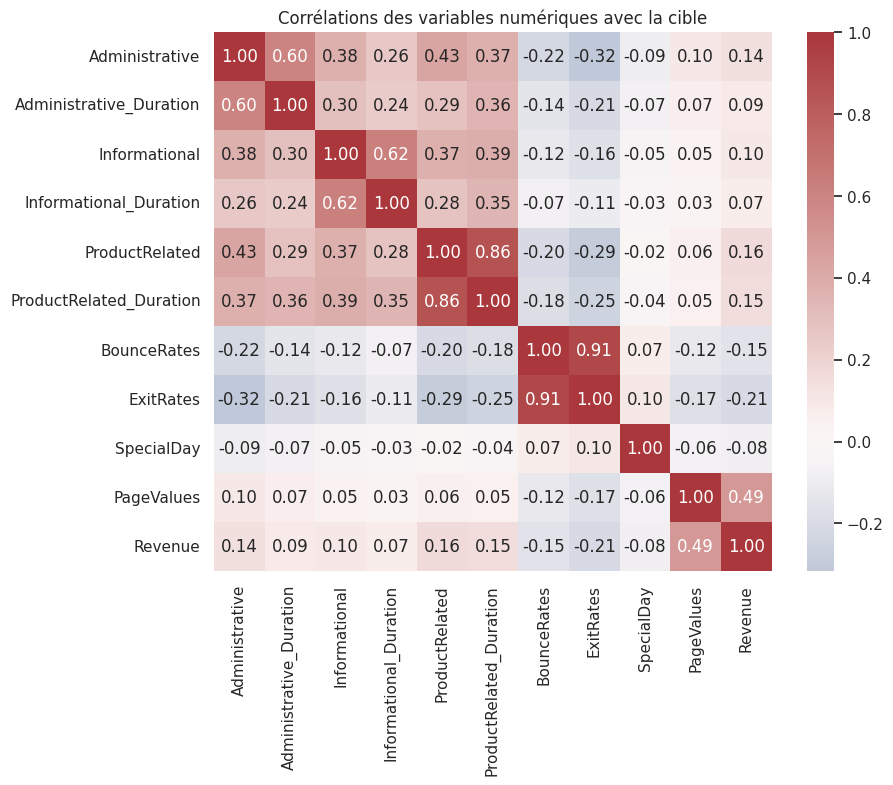

In [12]:
num = NUM_COLS + [LEAKY_COL]
plt.figure(figsize=(9, 7))
sns.heatmap(raw[num + [TARGET]].astype(float).corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Corrélations des variables numériques avec la cible")
plt.show()

### 1.5 bis Qu'est-ce qui distingue les acheteurs ?

Comparaison acheteurs / non-acheteurs sur les variables **connues pendant la visite** (donc sans `PageValues`).

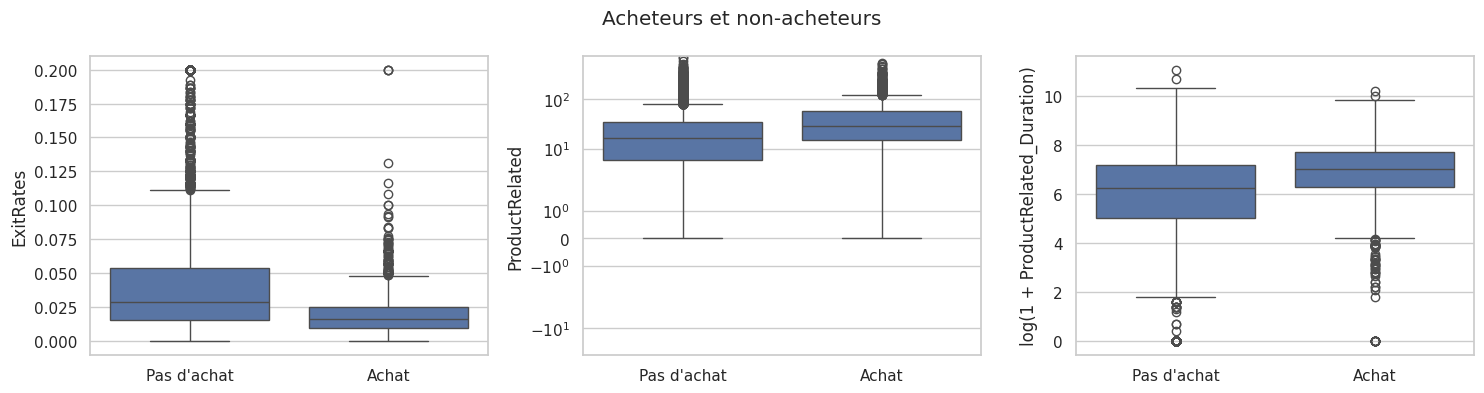

         ExitRates  BounceRates  ProductRelated  ProductRelated_Duration
Revenue                                                                 
False        0.029        0.004            16.0                  510.190
True         0.016        0.000            29.0                 1109.906

Corrélation de Spearman avec l'achat :
ExitRates                 -0.25
BounceRates               -0.15
SpecialDay                -0.09
Informational_Duration     0.11
Informational              0.11
Administrative_Duration    0.16
Administrative             0.17
ProductRelated             0.20
ProductRelated_Duration    0.22
PageValues                 0.63
dtype: float64


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=TARGET, y="ExitRates", data=raw, ax=axes[0])
sns.boxplot(x=TARGET, y="ProductRelated", data=raw, ax=axes[1])
axes[1].set_yscale("symlog")
sns.boxplot(x=TARGET, y=np.log1p(raw["ProductRelated_Duration"]), data=raw, ax=axes[2])
axes[2].set_ylabel("log(1 + ProductRelated_Duration)")
for ax in axes:
    ax.set_xticks([0, 1], ["Pas d'achat", "Achat"])
    ax.set_xlabel("")
plt.suptitle("Acheteurs et non-acheteurs")
plt.tight_layout()
plt.show()

print(raw.groupby(TARGET)[["ExitRates", "BounceRates", "ProductRelated", "ProductRelated_Duration"]].median().round(3))

# Corrélation de Spearman (sur les rangs) : plus fiable que Pearson pour des variables très asymétriques
print("\nCorrélation de Spearman avec l'achat :")
print(raw[NUM_COLS + [LEAKY_COL]].corrwith(raw[TARGET].astype(int), method="spearman").sort_values().round(2))

### 1.5 ter Variables à surveiller : `SpecialDay` et codes rares

In [14]:
print("SpecialDay > 0 seulement pour les mois :", sorted(raw.loc[raw["SpecialDay"] > 0, "Month"].unique()))
print("(proximité de la Saint-Valentin en février et de la fête des mères en mai : redondant en partie avec Month)\n")

for col in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
    counts = raw[col].value_counts()
    rares = counts[counts < 30]
    print(f"{col:16s} {len(counts):2d} codes, dont {len(rares)} rares (< 30 sessions) : {rares.to_dict()}")

SpecialDay > 0 seulement pour les mois : ['Feb', 'May']
(proximité de la Saint-Valentin en février et de la fête des mères en mai : redondant en partie avec Month)

OperatingSystems  8 codes, dont 3 rares (< 30 sessions) : {6: 19, 7: 7, 5: 6}
Browser          13 codes, dont 3 rares (< 30 sessions) : {12: 10, 11: 6, 9: 1}
Region            9 codes, dont 0 rares (< 30 sessions) : {}
TrafficType      20 codes, dont 6 rares (< 30 sessions) : {19: 17, 14: 13, 18: 10, 16: 3, 12: 1, 17: 1}


### 1.6 Constats

- **Qualité :** aucune valeur manquante. 125 lignes en double (201 lignes concernées) : ce sont toutes des rebonds (1 page, 0 seconde, aucun achat), donc probablement de vraies visites distinctes qui se ressemblent, et non des erreurs ; aucune étiquette contradictoire. Les durées sont très asymétriques : médiane d'environ 10 min sur les pages produits, mais 867 sessions de plus d'1 h et un maximum de 17,8 h (onglet sans doute resté ouvert) ; nous les conservons. 717 sessions ont des pages produits vues avec une durée nulle : Google Analytics ne mesure pas la durée de la dernière page, ce n'est pas une erreur. 6 sessions n'ont aucune page vue.
- **Déséquilibre :** seulement 15,5 % d'achats (1 908 sur 12 330). Un modèle qui répond toujours « pas d'achat » aurait 84,5 % d'exactitude sans détecter un seul acheteur : nous utiliserons le F1 et le rappel sur la classe « achat », et l'AUC.
- **`PageValues` :** 56 % d'achat quand elle est > 0, contre 4 % quand elle vaut 0 ; c'est de loin la variable la plus liée à l'achat (Pearson 0,49, Spearman 0,63). Mais elle est calculée à partir des transactions associées aux pages vues : pendant la visite, on connaît les pages, les durées, les taux de rebond et de sortie, le mois et le type de visiteur, mais pas la valeur exacte de la session (risque de fuite). Nous la testerons avec et sans.
- **Profil des acheteurs (sans `PageValues`) :** ils voient environ 2 fois plus de pages produits (médiane 29 contre 16), y restent 2 fois plus longtemps et quittent moins vite le site (`ExitRates`, Spearman −0,25).
- **Mois et visiteurs :** janvier et avril sont absents ; « June » est écrit en entier (corrigé en « Jun »). Le taux d'achat va de 1,6 % en février à 25,4 % en novembre ; il est plus élevé chez les nouveaux visiteurs (24,9 %) que chez les visiteurs réguliers (13,9 %). `SpecialDay` n'est non nul qu'en février et en mai : elle double en partie l'information du mois.
- **Catégories codées en nombres :** `OperatingSystems` (8 codes), `Browser` (13), `Region` (9) et `TrafficType` (20) sont des catégories : la région 8 n'est pas « plus grande » que la région 2. Elles passent en one-hot comme `Month` et `VisitorType`. 12 codes ont moins de 30 sessions (dont 6 pour `TrafficType`) : nous les gardons, un regroupement est possible plus tard.

# Partie 2 · Préparation

### 2.1 Nettoyage sans apprentissage

**Pourquoi retirer les doublons alors que ce sont probablement de vraies visites (section 1.2 bis) ?** Une même ligne pourrait se retrouver à la fois dans l'entraînement et dans le test : le modèle serait alors évalué sur des exemples déjà vus (fuite). Les 125 lignes retirées sont toutes des rebonds sans achat ; l'effet sur la répartition est négligeable (15,5 % → 15,6 % d'achats). Choix prudent, assumé.

In [15]:
df = clean(raw)
print("Lignes avant :", len(raw), "| après suppression des doublons :", len(df))
print(sorted(df["Month"].unique()))

Lignes avant : 12330 | après suppression des doublons : 12205
['Aug', 'Dec', 'Feb', 'Jul', 'Jun', 'Mar', 'May', 'Nov', 'Oct', 'Sep']


### 2.2 Séparer **avant** de préparer

Le découpage est stratifié pour garder environ 15 % d'achats dans le train **et** dans le test.

In [16]:
X_train, X_test, y_train, y_test = split(df)
print("Entraînement :", X_train.shape, "| Test :", X_test.shape)
print("Taux d'achat train :", round(y_train.mean(), 3), "| test :", round(y_test.mean(), 3))

Entraînement : (9764, 17) | Test : (2441, 17)
Taux d'achat train : 0.156 | test : 0.156


### 2.3 Encoder et normaliser avec un `ColumnTransformer`

`fit` sur l'entraînement uniquement ; le test est seulement **transformé**.

In [17]:
for name in FEATURE_SETS:
    prep = make_preprocessor(name)
    Xtr = prep.fit_transform(X_train)
    Xte = prep.transform(X_test)
    print(f"{name:16s} -> train {Xtr.shape} | test {Xte.shape}")

prep = make_preprocessor("sans_PageValues").fit(X_train)
print("\nExemples de colonnes créées :", list(prep.get_feature_names_out()[:12]))

sans_PageValues  -> train (9764, 72) | test (2441, 72)
avec_PageValues  -> train (9764, 73) | test (2441, 73)

Exemples de colonnes créées : ['num__Administrative', 'num__Administrative_Duration', 'num__Informational', 'num__Informational_Duration', 'num__ProductRelated', 'num__ProductRelated_Duration', 'num__BounceRates', 'num__ExitRates', 'num__SpecialDay', 'cat__Month_Aug', 'cat__Month_Dec', 'cat__Month_Feb']


### 2.4 Préparer une nouvelle session (comme le fera l'application)

In [18]:
nouvelle_session = X_test.iloc[[0]]
display(nouvelle_session)
print(prep.transform(nouvelle_session).round(2))

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
11640,0,0.0,0,0.0,12,482.5,0.02,0.04,0.0,0.0,Nov,1,2,1,10,Returning_Visitor,0


[[-0.7  -0.46 -0.4  -0.24 -0.45 -0.38 -0.01 -0.03 -0.31  0.    0.    0.
   0.    0.    0.    0.    1.    0.    0.    0.    0.    1.    1.    0.
   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    1.
   0.    0.    0.    0.    0.    0.    0.    1.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    1.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.  ]]


## Bilan J1

- **Ce que nous avons appris sur les données :** 12 330 sessions d'un seul site sur une année (sans janvier ni avril), sans valeur manquante mais déséquilibrées (15,5 % d'achats). Les acheteurs consultent plus de pages produits et sortent moins vite ; `PageValues` est très prédictive mais suspecte de fuite.
- **Décisions de préparation et pourquoi :** doublons retirés avant le découpage (une même ligne dans le train et le test serait une fuite ; effet négligeable : 15,5 % → 15,6 %) ; découpage 80 / 20 stratifié avec `random_state` = 42 **avant** toute préparation ; `StandardScaler` sur les variables numériques et `OneHotEncoder` sur les codes, ajustés sur l'entraînement uniquement. Résultat : 9 764 sessions d'entraînement et 2 441 de test, mises de côté jusqu'au notebook 3.
- **Ce qui sera testé en J2 :** modèles avec et sans `PageValues`.